# 06 · Spatial structure and scales
Moran's I distance decay and LISA (`src/spatial_mining.py`); Moran eigenvector maps and variation partitioning;
Bernoulli scan statistic and its alignment with wards (`src/spatial_analysis.py`).

In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
M, F = ROOT / "results/metrics", ROOT / "results/figures"
def table(name, **kw):
    t = pd.read_csv(M / name, **kw)
    return t.round(4)
def fig(name, width=1100):
    display(Image(filename=str(F / name), width=width))

In [2]:
display(table("spatial_autocorrelation_distance_decay.csv")); table("lisa_cluster_summary.csv")

,k_neighbors,mean_neighbor_distance_m,morans_i,z_score,p_value
0,3,162.4824,0.2788,27.3387,0.001
1,5,215.9884,0.2444,30.8200,0.001
2,7,261.9850,0.2234,33.3593,0.001
3,10,321.6870,0.2043,36.7727,0.001
4,15,405.2898,0.1888,41.2512,0.001
5,20,477.0471,0.1792,45.4339,0.001


,cluster,n_springs_fdr_q<0.05,n_springs_uncorrected_p<0.05
0,Not significant,5564,5120
1,High-High (dried cluster),95,354
2,Low-High (active among dried),30,215


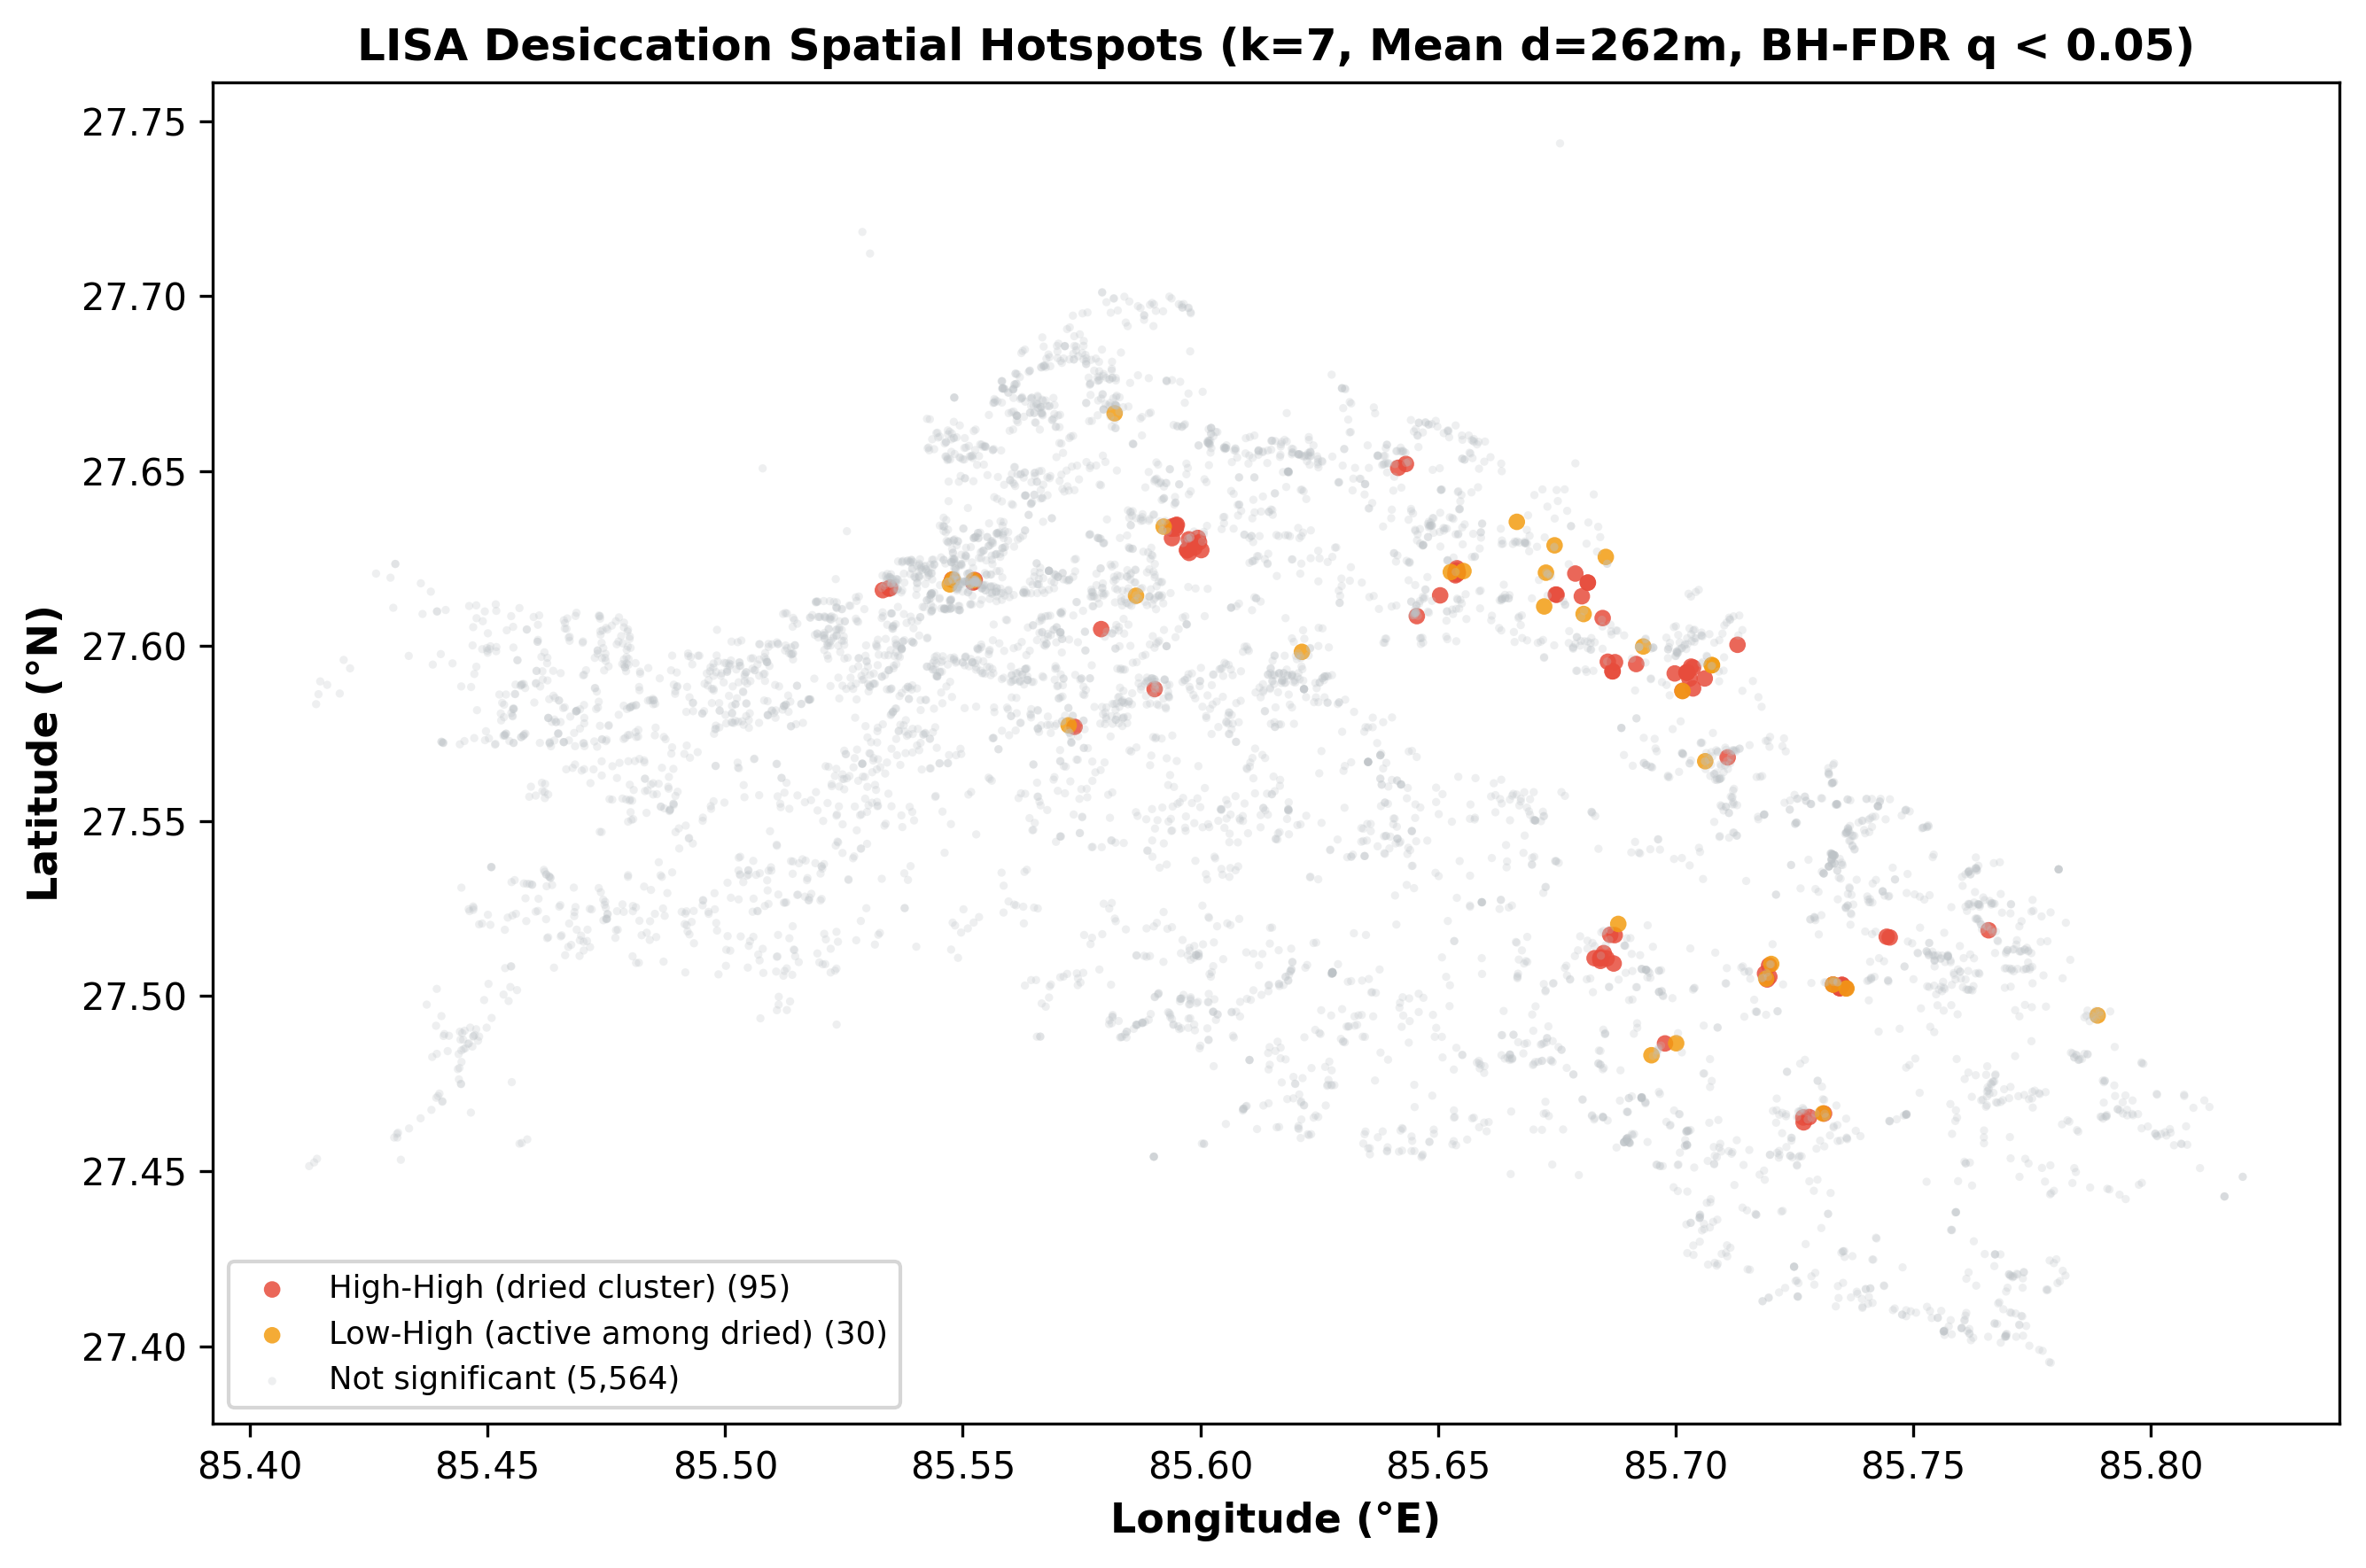

In [3]:
fig("lisa_cluster_map.png", 700)

## Environment vs space (Moran eigenvector maps)

,fraction,adj_pseudo_r2
0,[a] environment only,0.0598
1,[b] shared (spatially structured environment),0.0526
2,[c] space only (MEMs),0.0340
3,[d] unexplained,0.8536


,scale,n_mem,r2_space_alone,r2_unique_beyond_env
0,broad (MEM 1-25),25,0.0149,0.0093
1,meso (MEM 26-100),75,0.0581,0.0189
2,fine (MEM 101-250),150,0.0136,0.0075


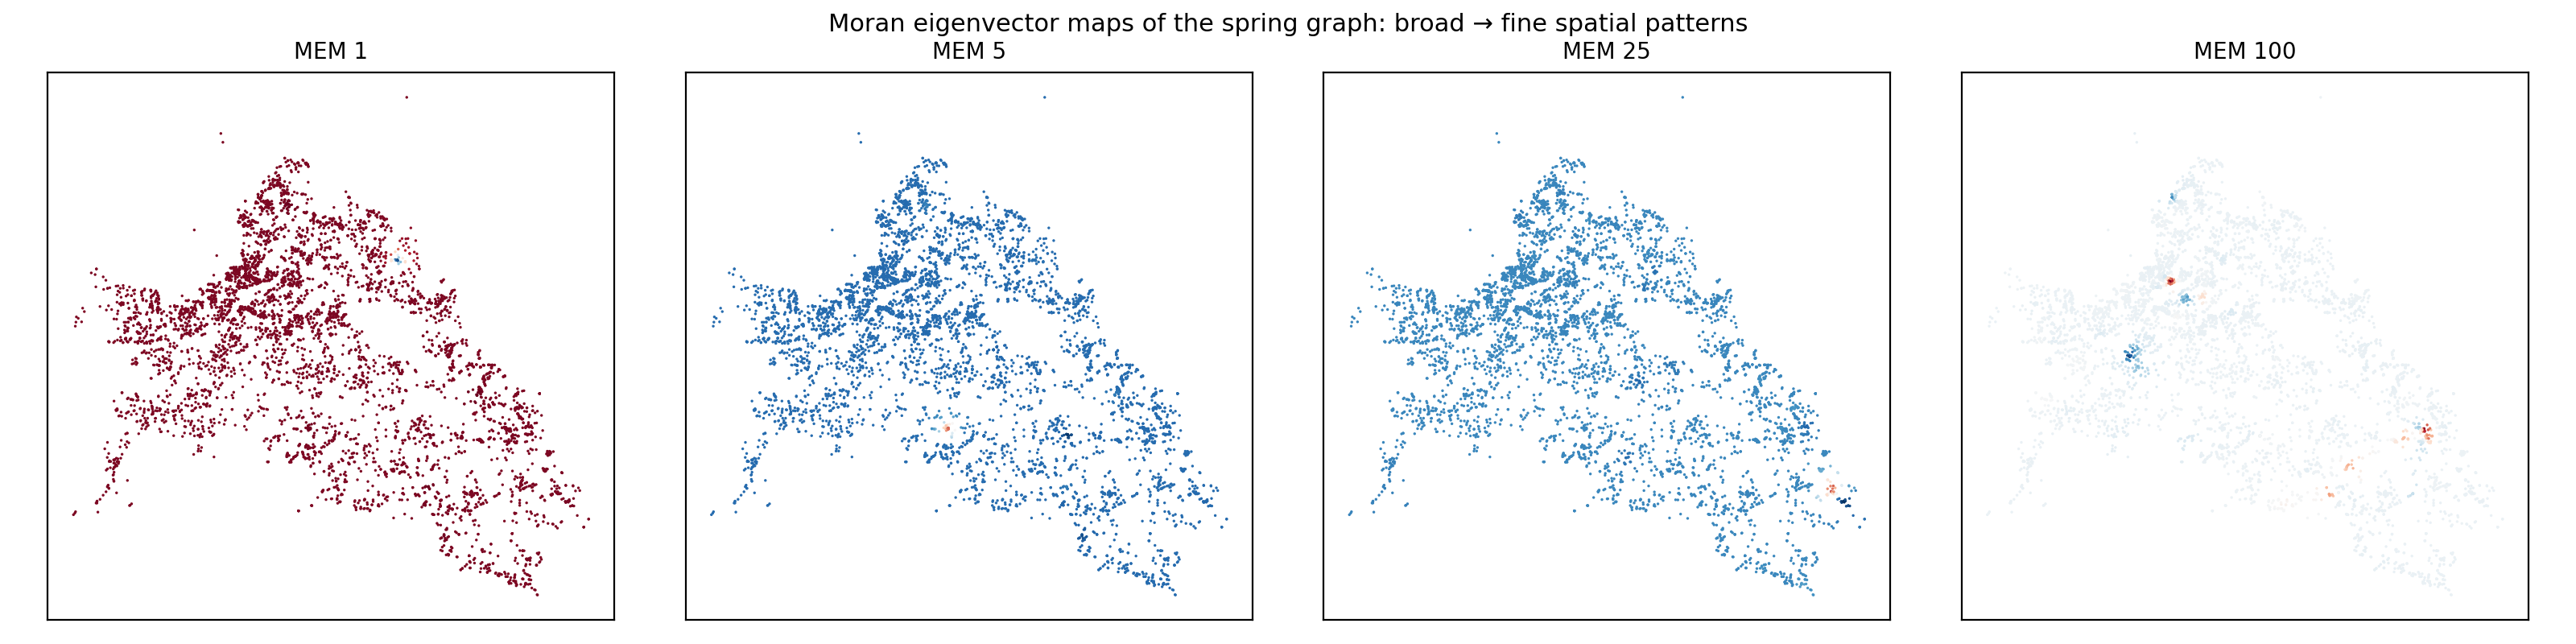

In [4]:
display(table("sa_variation_partitioning.csv")); display(table("sa_variation_by_scale.csv")); fig("sa_mem_examples.png")

## Scan statistic clusters

In [5]:
display(table("sa_scan_clusters.csv").drop(columns=["center_index"])); table("sa_scan_ward_alignment.csv")

,rank,radius_m,n_sources,cases,observed_rate,rate_outside,relative_risk,llr,p_value,center_lat,center_lon,analysis
0,1,4815.2484,386,218,0.5648,0.2457,2.2985,81.9935,0.001,27.5997,85.6923,dried (high)
1,2,5239.2107,494,227,0.4595,0.2491,1.8448,46.2148,0.001,27.4820,85.7591,dried (high)
2,3,1393.5034,83,59,0.7108,0.2608,2.7257,36.0016,0.001,27.6294,85.5980,dried (high)
3,4,426.8093,85,53,0.6235,0.2620,2.3803,23.9939,0.001,27.6186,85.5512,dried (high)
4,5,601.9594,26,21,0.8077,0.2649,3.0493,16.6188,0.001,27.5145,85.6853,dried (high)
5,6,719.9537,34,25,0.7353,0.2645,2.7795,16.2442,0.001,27.5769,85.5735,dried (high)
6,7,395.2906,29,21,0.7241,0.2650,2.7324,13.1895,0.009,27.6164,85.5364,dried (high)
7,8,318.6770,17,14,0.8235,0.2657,3.0996,11.5199,0.047,27.6145,85.5865,dried (high)
8,9,393.6598,12,11,0.9167,0.2660,3.4463,11.4072,0.058,27.6523,85.6433,dried (high)
9,1,8842.0205,548,43,0.0785,0.2875,0.2729,68.3625,0.001,27.5936,85.4211,dried (low)


,analysis,rank,n_sources,relative_risk,majority_municipality,n_wards_spanned,dominant_ward_share,null_mean_share,percentile_vs_random_windows
0,dried (high),1,386,2.2985,Panchkhal,9,0.2513,0.2647,0.468
1,dried (high),2,494,1.8448,Temal,10,0.1903,0.2162,0.290
2,dried (high),3,83,2.7257,Panchkhal,4,0.5422,0.6605,0.300
3,dried (high),4,85,2.3803,Dhulikhel,4,0.4824,0.6387,0.196
4,dried (high),5,26,3.0493,Roshi RM,2,0.9615,0.8460,0.526
5,dried (high),6,34,2.7795,Dhulikhel,2,0.9706,0.8160,0.674
6,dried (high),7,29,2.7324,Dhulikhel,3,0.7931,0.8215,0.368
7,dried (high),8,17,3.0996,Dhulikhel,1,1.0000,0.8780,0.480
8,dried (low),1,548,0.2729,Panauti,9,0.2044,0.2023,0.636
9,dried (low),2,303,0.3212,Dhulikhel,6,0.5314,0.3162,0.972


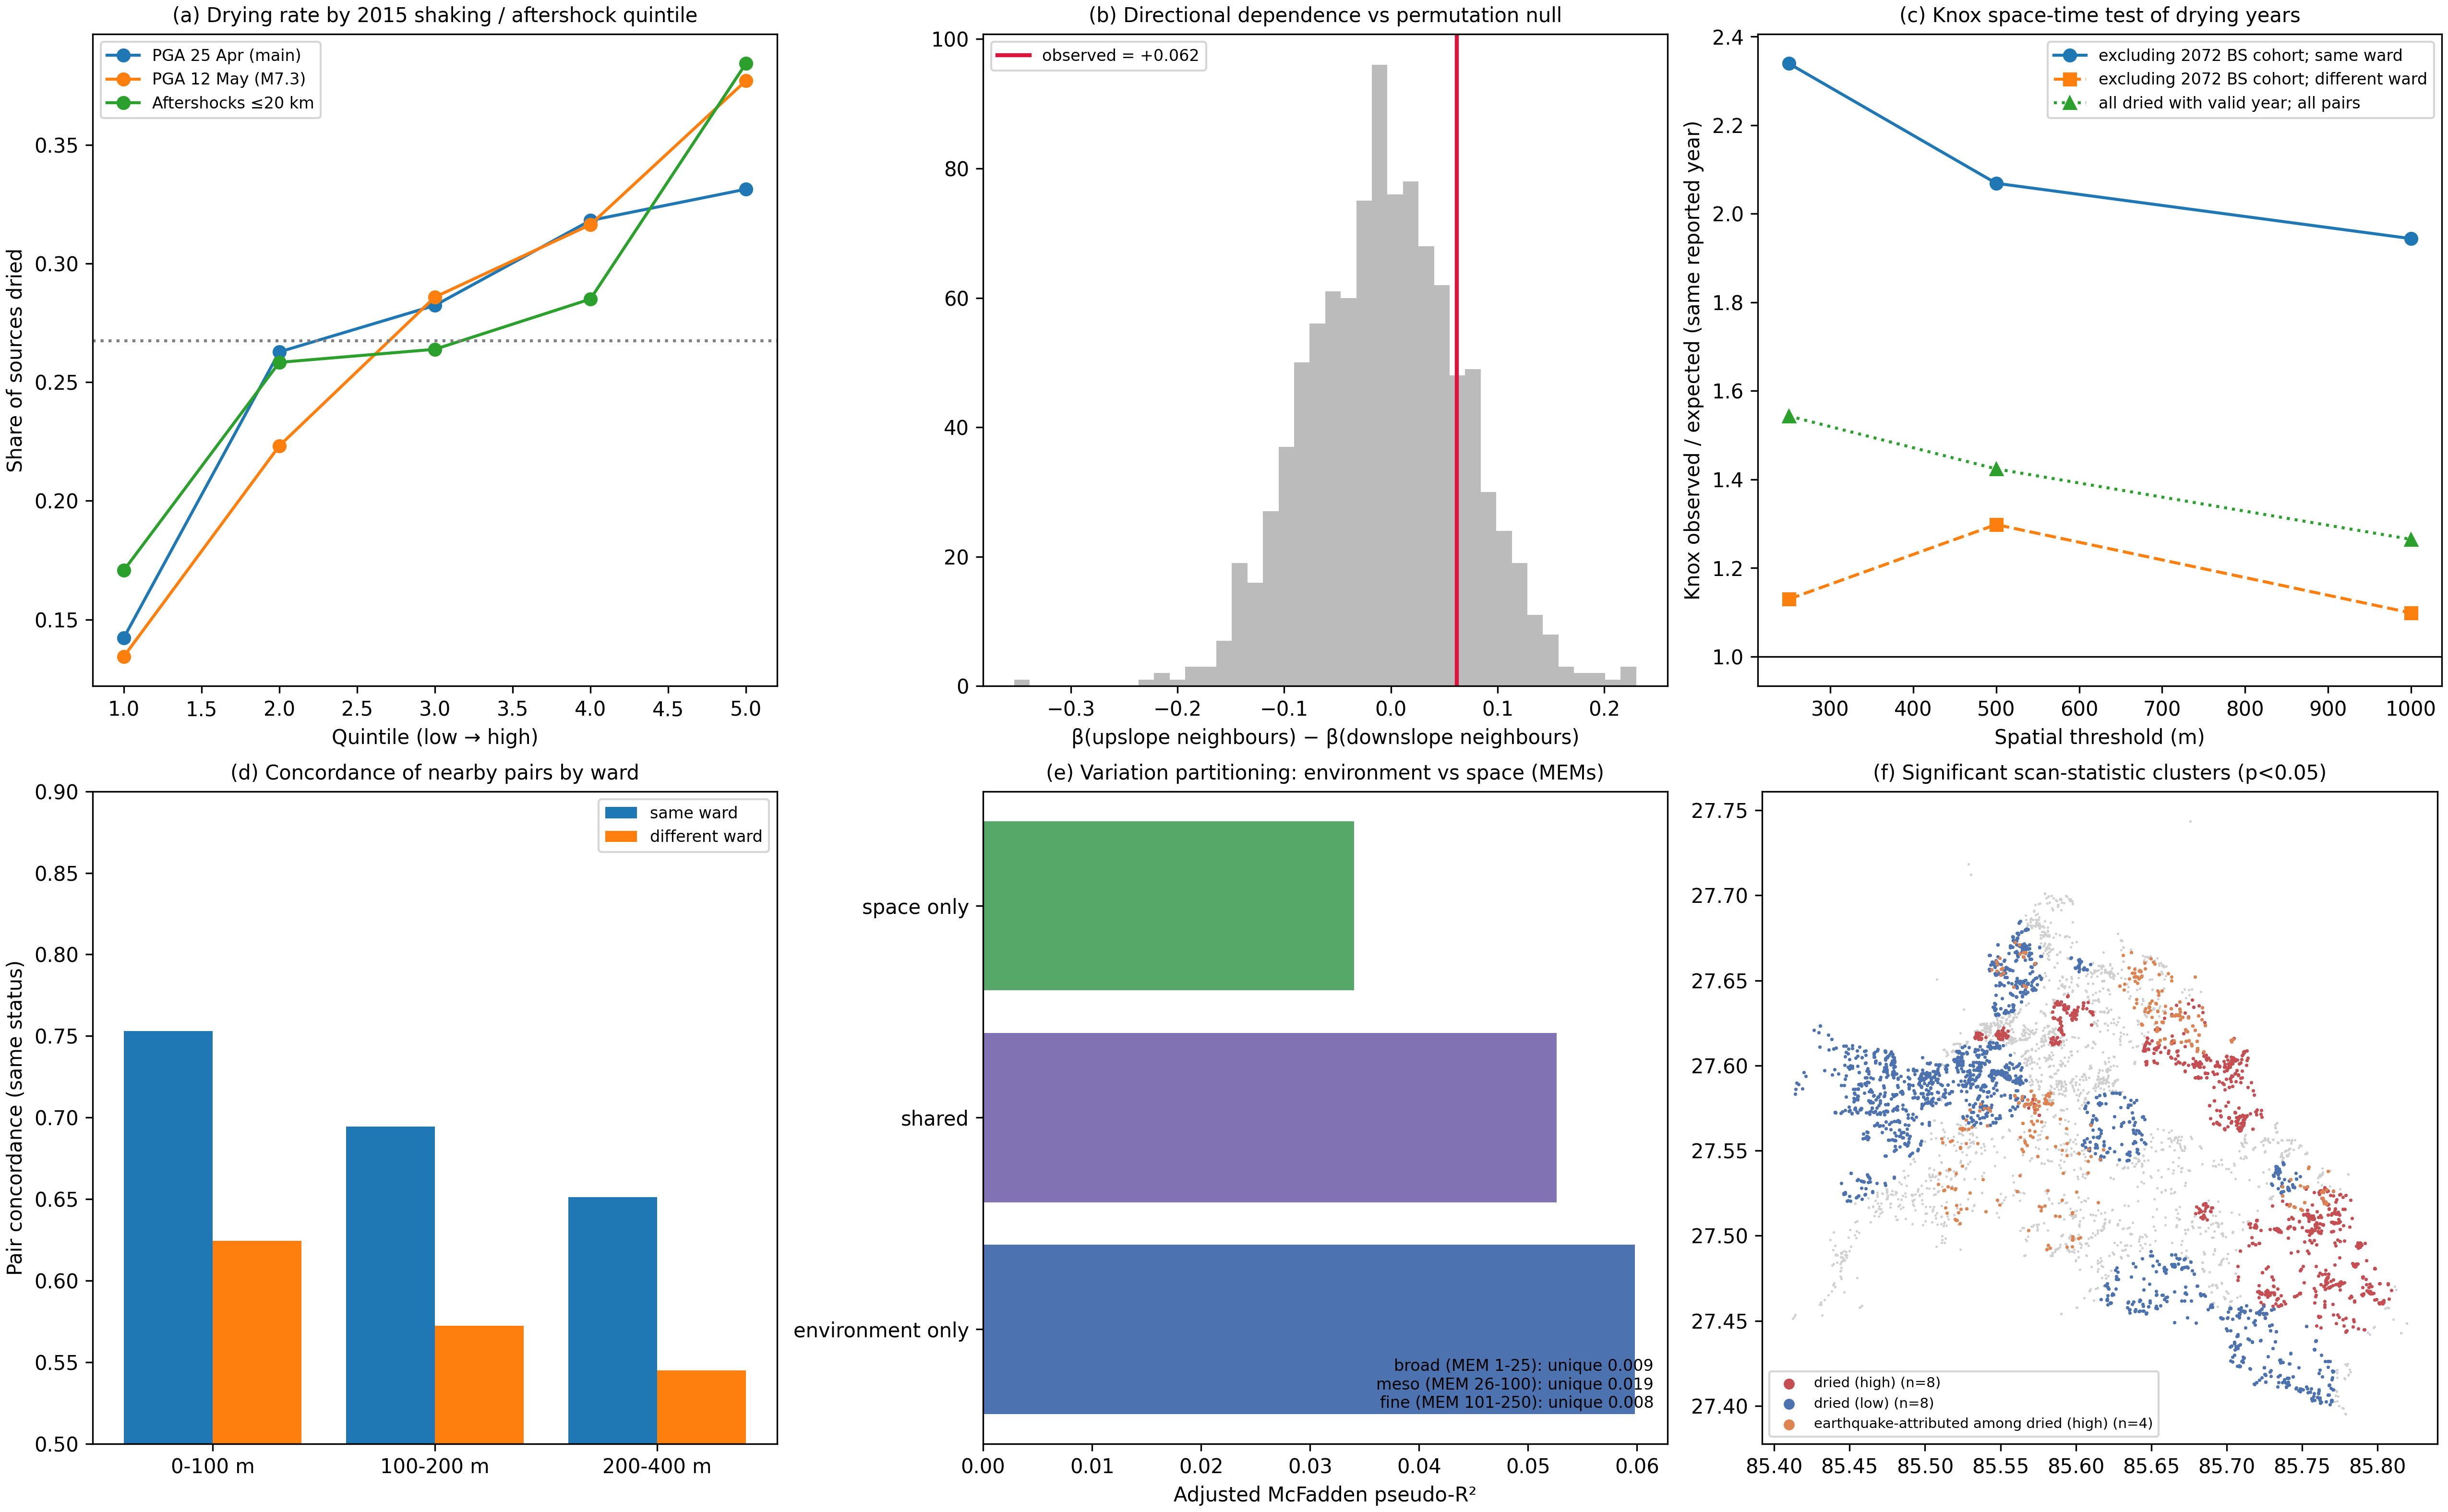

In [6]:
fig("sa_spatial_data_mining.png")